# 03 · Baseline Rules

**Goal:** use notebook 02's clues to make one decision per time entry, score it against the answer key, and set the baseline the classifier (notebook 04) has to beat.

Every entry gets one of five decisions:

| decision | meaning | what the app shows |
|---|---|---|
| `AUTO_MATCH` | accept the matter, no review | fields filled in and highlighted as generated |
| `FLAG_MISMATCH` | typed fields and narrative disagree, or the matter wasn't open | a flag, with a suggested matter when one stands out |
| `NEEDS_REVIEW` | a person decides | a shortlist of likely matters |
| `SPLIT_ENTRY` | the entry covers two matters | both matters |
| `NO_MATCH` | the client or matter isn't in Matter Master | a "send to intake" message |

**Two methods, scored the same way**
1. **Status quo:** accept any valid typed CMID and send everything else to review. This is roughly what billing staff do today.
2. **Rules:** find the client, then compare what was typed with what the narrative says. **This is the baseline for notebook 04.**

**Questions**
1. How much review do the rules save compared with the status quo, and how accurate are they?
2. Which settings work best on TRAIN?
3. Where do the rules still fail?
4. Do the results hold on VAL?

## 1. Setup

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "../src")
from rules import ACTIONS, OUTCOMES, DEFAULTS, decide, status_quo, run_rules, answer_key, score, summarize

In [2]:
RESULTS_DIR = Path("../results")
TUNE, CHECK = "TRAIN", "VAL"

PRECISION_TARGET = 0.98   # at most about 1 wrong decision in 50 among those made without a person

CUTOFFS = {
    "client_min": [60, 65, 70, 75, 80, 85, 90, 95, 100],
    "matter_min": [60, 65, 70, 75, 80, 85, 90, 95, 100],
    "no_match_max": [50, 60, 65, 70, 75, 80, 85, 90],
}
SWITCHES = {   # starting value first
    "accept_cue_only": [True, False],
    "split_other_client": [False, True],
    "flag_cue_conflict": [False, True],
    "flag_contact_conflict": [False, True],
    "require_history": [False, True],
    "cue_fit_agrees": [False, True],
    "history_within_client": [False, True],
    "bad_cmid_use_text": [True, False],
    "bad_cmid_accept_closest": [False, True],
    "bad_cmid_fallback": ["NEEDS_REVIEW", "NO_MATCH"],
}

## 2. Load data

The pairs table from notebook 02 has 103 rows per entry, one per candidate matter. The answer key (`key_` columns) is only used for scoring.

In [3]:
pairs = pd.read_parquet(RESULTS_DIR / "02_pairs.parquet")
feature_config = json.loads((RESULTS_DIR / "02_config.json").read_text())
scorer_choice = json.loads((RESULTS_DIR / "01_scorer_choice.json").read_text())
answers = answer_key(pairs)

train_pairs = pairs[pairs["split"] == TUNE]
val_pairs = pairs[pairs["split"] == CHECK]

assert (pairs.groupby("entry_id").size() == pairs["cmid"].nunique()).all()
assert set(answers["key_expected_action"]) <= set(ACTIONS)
print(f"{len(pairs):,} pairs | {len(answers):,} entries | {TUNE}: {train_pairs['entry_id'].nunique():,} | {CHECK}: {val_pairs['entry_id'].nunique():,}")

412,000 pairs | 4,000 entries | TRAIN: 2,802 | VAL: 601


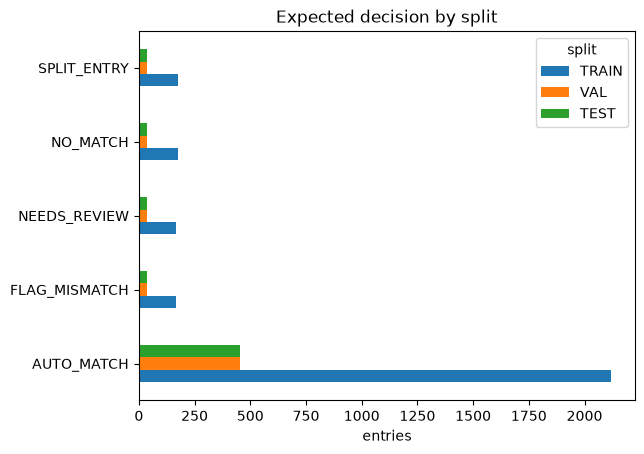

In [4]:
ax = answers.groupby(["key_expected_action", "split"]).size().unstack()[["TRAIN", "VAL", "TEST"]].plot.barh(title="Expected decision by split")
ax.set(xlabel="entries", ylabel="")
plt.show()

- About three quarters of entries should be auto-matched. Each of the other decisions has 35+ entries in VAL and TEST.
- About 5% of entries have a wrong CMID that nothing in the entry contradicts (`KEY: Silent Error = Y`). Any method that trusts a valid CMID gets these wrong, so they're reported separately as **silent by design**.
- About a quarter of entries are **trivial** (the typed CMID is already right), so results are also shown without them.

## 3. How the rules decide

The idea comes from record linkage: look at separate pieces of evidence, accept when they agree, and send the entry to a person when they disagree or there isn't enough to go on. The code is `decide` in `src/rules.py`.

**Step 1: find the client.** In order: the typed client name, the typed CMID's client number, a client named in the narrative, a client contact named in the narrative.

**Step 2: two votes.**
- **Typed vote:** a valid typed CMID, or else the one matter whose client and matter names both score above `client_min` and `matter_min`.
- **Narrative vote:** a key term for one matter, or a shared key term ("Fund II") at the client, or the client's matter whose type has the most task cues (ties broken by timekeeper history).

**Step 3: checks.** The first one that applies decides.

| # | if... | then |
|---|---|---|
| 1 | the narrative names two or more matters by their own key terms | `SPLIT_ENTRY` |
| 2 | a client or matter was typed, nothing in Matter Master scores above `no_match_max`, and nothing else points anywhere | `NO_MATCH` |
| 3 | the typed CMID doesn't exist | accept the narrative's matter if it fits the CMID; `NO_MATCH` if the client number is unknown too; otherwise review with the closest CMID |
| 4 | both votes agree | `AUTO_MATCH` |
| 5 | the votes disagree | `FLAG_MISMATCH`, suggesting the narrative's matter |
| 6 | only one vote | `AUTO_MATCH` |
| 7 | no vote | `NEEDS_REVIEW` with a top-3 shortlist |
| always | the matter about to be accepted wasn't open on the work date | `FLAG_MISMATCH` |

Short client fields like "PRH" or "NGB" are skipped by check 2. On TRAIN, only 3 of 169 are actually new clients; the rest are shorthand for real ones.

**On/off settings**, tuned in section 5:

| setting | when on |
|---|---|
| `accept_cue_only` | a narrative vote from task cues alone can be auto-accepted |
| `split_other_client` | also split when a multi-part narrative names a matter at another client |
| `flag_cue_conflict` | flag a typed-only match when every task cue points to other types of work |
| `flag_contact_conflict` | flag a typed-only match when only other clients' contacts are named |
| `require_history` | a typed-only match has to be in the timekeeper's history (unless the matter is newer than the history) |
| `cue_fit_agrees` | a task-cue vote for another matter doesn't count against a typed match whose type also has cues |
| `history_within_client` | with no cues, the narrative vote can be the only client matter the timekeeper has billed |
| `bad_cmid_use_text` | check 3 can accept the narrative's matter |
| `bad_cmid_accept_closest` | check 3 accepts the closest CMID when the narrative is silent |
| `bad_cmid_fallback` | what check 3 does when nothing else decides: `NEEDS_REVIEW` or `NO_MATCH` |

### Scoring

| measure | meaning |
|---|---|
| `auto_precision` | share of auto-accepts that are right. A wrong one is a **silent error**: it goes on the bill with nobody checking. |
| `decided_precision` | share of `AUTO_MATCH` and `NO_MATCH` decisions that are right. Both skip a reviewer, so **tuning uses this one**. |
| `review_share` | share of entries sent to a person. Safe, but costs time. |
| `silent_errors` | wrong auto-accepts, split into `silent_by_design` and `silent_catchable` |
| `action_accuracy` | share of entries given the expected decision |

A split counts as right only if both matters are right. For splits where the narrative doesn't name the second matter, the primary matter is enough.

In [5]:
start = DEFAULTS | {"client_col": feature_config["client_col"], "matter_col": feature_config["matter_col"],
                    "phrase_min": feature_config["phrase_min"], "no_match_max": scorer_choice["no_match_cutoff"]}


def evaluate(table, cfg, method=decide):
    return score(run_rules(table, cfg, method), answers)


example = evaluate(train_pairs[train_pairs["entry_id"].isin(answers.query("key_entry_category == 'WRONG_CMID_TEXT'")["entry_id"].head(20))], start)
example.loc[example["action"] == "FLAG_MISMATCH", ["entry_id", "typed_vote", "typed_source", "text_vote", "text_source",
                                                   "action", "pred_cmid", "key_true_cmid"]].head(3)

,entry_id,typed_vote,typed_source,text_vote,text_source,action,pred_cmid,key_true_cmid
0,T-00048,4590.001,typed CMID,4590.004,key term,FLAG_MISMATCH,4590.004,4590.004
6,T-00390,3455.003,typed CMID,3455.002,task cue,FLAG_MISMATCH,3455.002,3455.002
9,T-00691,2960.002,typed CMID,2960.003,task cue,FLAG_MISMATCH,2960.003,2960.003


These are wrong-CMID entries: the typed CMID votes for one matter and the narrative names another, so the rules flag them and suggest the narrative's matter.

## 4. Status quo vs. rules on TRAIN (starting settings)

In [6]:
start_runs = {"status quo": evaluate(train_pairs, start, status_quo), "rules": evaluate(train_pairs, start)}
pd.DataFrame({name: summarize(scored) for name, scored in start_runs.items()}).T.round(3)

,entries,action_accuracy,auto_share,auto_precision,decided_precision,silent_errors,silent_by_design,silent_catchable,review_share,flag_share,flag_suggestion_right,shortlist_hit,no_match_share,no_match_precision
status quo,2802.0,0.424,0.451,0.698,0.698,381.0,139.0,242.0,0.549,0.000,NaN,0.70,0.000,NaN
rules,2802.0,0.724,0.663,0.805,0.808,362.0,138.0,224.0,0.222,0.073,0.319,0.51,0.036,0.863


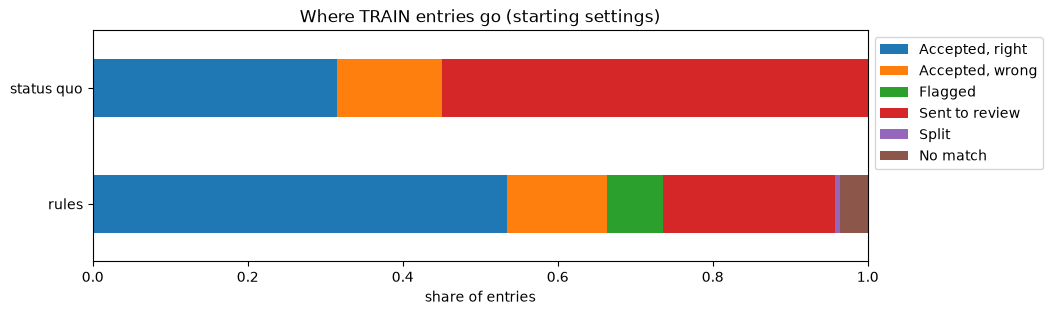

In [7]:
def outcome_shares(runs):
    return pd.DataFrame({name: scored["outcome"].value_counts(normalize=True) for name, scored in runs.items()}).T[OUTCOMES].fillna(0)


ax = outcome_shares(start_runs).plot.barh(stacked=True, figsize=(10, 3), xlim=(0, 1), title=f"Where {TUNE} entries go (starting settings)")
ax.set_xlabel("share of entries")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
ax.invert_yaxis()
plt.show()

- **The status quo** sends 55% of entries to review, and only 70% of what it accepts is right, since it can't catch a wrong CMID.
- **The rules** cut review to 22% and raise auto precision to 81%, but silent errors barely drop (381 to 362) because the starting settings still trust a valid CMID when the narrative says nothing.

## 5. Tune the rules on TRAIN

**Selection rule:** among settings with `decided_precision` of at least 98%, pick the lowest `review_share`, then the highest `action_accuracy`. If none reach 98%, pick the highest `decided_precision`, then the lowest `review_share`.

### Cutoffs

One cutoff changes at a time while the others stay at their starting values. This takes a few minutes.

Chosen cutoffs: {'client_min': 70, 'matter_min': 85, 'no_match_max': 75}


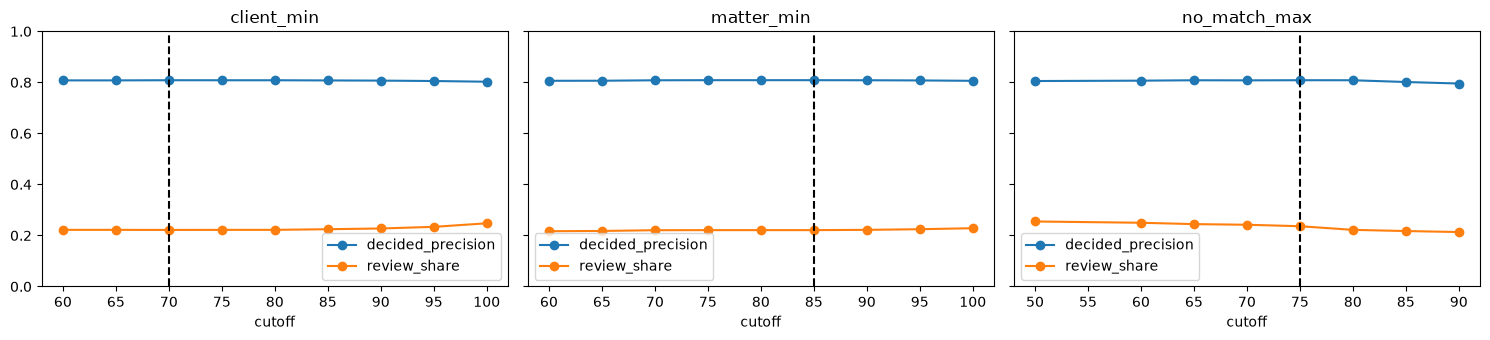

In [8]:
METRICS = ["decided_precision", "review_share", "action_accuracy"]


def pick_best(results):
    ok = results[results["decided_precision"] >= PRECISION_TARGET]
    if ok.empty:
        return results.sort_values(["decided_precision", "review_share"], ascending=[False, True]).index[0]
    return ok.sort_values(["review_share", "action_accuracy"], ascending=[True, False]).index[0]


sweeps = {}
for setting, values in CUTOFFS.items():
    sweeps[setting] = pd.DataFrame({v: summarize(evaluate(train_pairs, start | {setting: v})) for v in values}).T

tuned = dict(start)
for setting, results in sweeps.items():
    best = results.loc[pick_best(results), METRICS]
    ties = results[(results[METRICS] == best).all(axis=1)].index
    tuned[setting] = min(ties, key=lambda v: abs(v - start[setting]))
print("Chosen cutoffs:", {s: tuned[s] for s in CUTOFFS})

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5), sharey=True)
for ax, (setting, results) in zip(axes, sweeps.items()):
    results[["decided_precision", "review_share"]].plot(ax=ax, marker="o", title=setting, ylim=(0, 1))
    ax.axvline(tuned[setting], color="black", linestyle="--")
    ax.set_xlabel("cutoff")
plt.tight_layout()
plt.show()

- No cutoff reaches 98%, so each one is picked by the fallback (highest precision, then lowest review).
- `client_min` and `matter_min` hardly matter below 85: a typed name is either close to a real one or far off.
- `no_match_max` trades review for `NO_MATCH` calls. Above 80, real clients start getting called new.

### On/off settings

Ten on/off settings make 1,024 combinations, so they're added one at a time (forward selection): each round tries flipping every setting that's still at its starting value, keeps the best flip, and stops when nothing improves. This takes several minutes.

In [9]:
current = tuned
current_summary = summarize(evaluate(train_pairs, current))
remaining = list(SWITCHES)
round_one = {"(starting values)": current_summary}

while remaining:
    tried = {s: summarize(evaluate(train_pairs, current | {s: SWITCHES[s][1]})) for s in remaining}
    if len(round_one) == 1:
        round_one.update(tried)
    results = pd.DataFrame(tried).T
    best = pick_best(results)
    both = pd.DataFrame([tried[best], current_summary], index=["new", "current"])
    if pick_best(both) != "new" or (both.loc["new", METRICS] == both.loc["current", METRICS]).all():
        break
    current = current | {best: SWITCHES[best][1]}
    current_summary = tried[best]
    remaining.remove(best)
    print(f"keep {best} = {SWITCHES[best][1]} | decided precision {current_summary['decided_precision']:.3f}, review {current_summary['review_share']:.3f}")

chosen = current

keep require_history = True | decided precision 0.847, review 0.305
keep accept_cue_only = False | decided precision 0.868, review 0.390
keep split_other_client = True | decided precision 0.874, review 0.389
keep flag_contact_conflict = True | decided precision 0.877, review 0.386
keep flag_cue_conflict = True | decided precision 0.879, review 0.382
keep cue_fit_agrees = True | decided precision 0.880, review 0.382


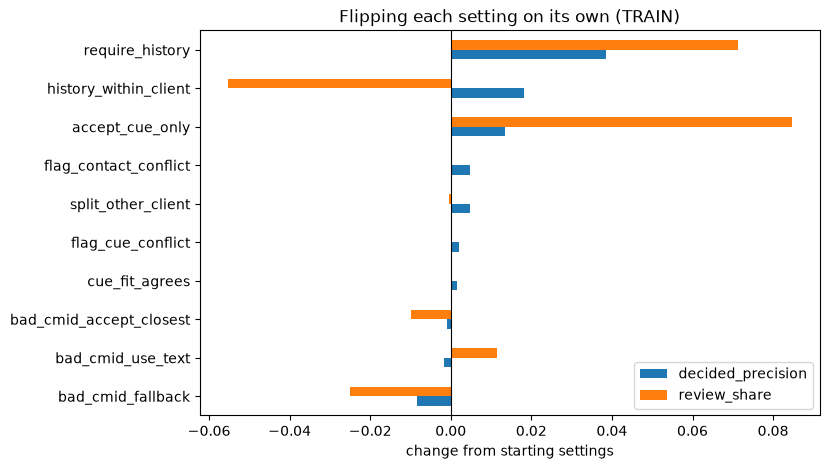

In [10]:
round_one = pd.DataFrame(round_one).T
change = (round_one[["decided_precision", "review_share"]] - round_one.loc["(starting values)", ["decided_precision", "review_share"]]).drop("(starting values)")
ax = change.sort_values("decided_precision").plot.barh(figsize=(8, 5), title=f"Flipping each setting on its own ({TUNE})")
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("change from starting settings")
plt.show()

- **No combination reaches 98% on TRAIN**, so forward selection keeps whatever raises precision most, even when it adds review.
- **Two settings do most of the work:** `require_history` (+4 points of precision, +7 of review) and turning off `accept_cue_only` (+1 point, +8 of review). The other kept settings add less than 1 point each.
- **`history_within_client` saves the most review** (−6 points with precision up 2), but it isn't kept because it costs a little precision once `require_history` is on.
- **`bad_cmid_fallback = NO_MATCH`** lowers review but sends CMID typos to new-client intake, so it isn't kept.

In [11]:
pd.Series({s: chosen[s] for s in [*CUTOFFS, *SWITCHES]}, name="chosen").to_frame()

,chosen
client_min,70
matter_min,85
no_match_max,75
accept_cue_only,False
split_other_client,True
flag_cue_conflict,True
flag_contact_conflict,True
require_history,True
cue_fit_agrees,True
history_within_client,False


## 6. The chosen rules on TRAIN

### Expected vs. decided

Rows are what the answer key expects and columns are what the rules decided, so the diagonal is right. An `AUTO_MATCH` row sent to review costs time; a `FLAG_MISMATCH` row that was auto-accepted is a silent error.

In [12]:
chosen_train = evaluate(train_pairs, chosen).merge(train_pairs.drop_duplicates("entry_id")[["entry_id", "source_format"]], on="entry_id")
pd.crosstab(chosen_train["key_expected_action"], chosen_train["action"]).reindex(index=ACTIONS, columns=ACTIONS, fill_value=0)

action,AUTO_MATCH,FLAG_MISMATCH,NEEDS_REVIEW,SPLIT_ENTRY,NO_MATCH
key_expected_action,,,,,
AUTO_MATCH,1313,87,698,19,3
FLAG_MISMATCH,21,112,25,10,0
NEEDS_REVIEW,2,0,162,0,2
SPLIT_ENTRY,70,7,69,28,0
NO_MATCH,3,0,115,1,55


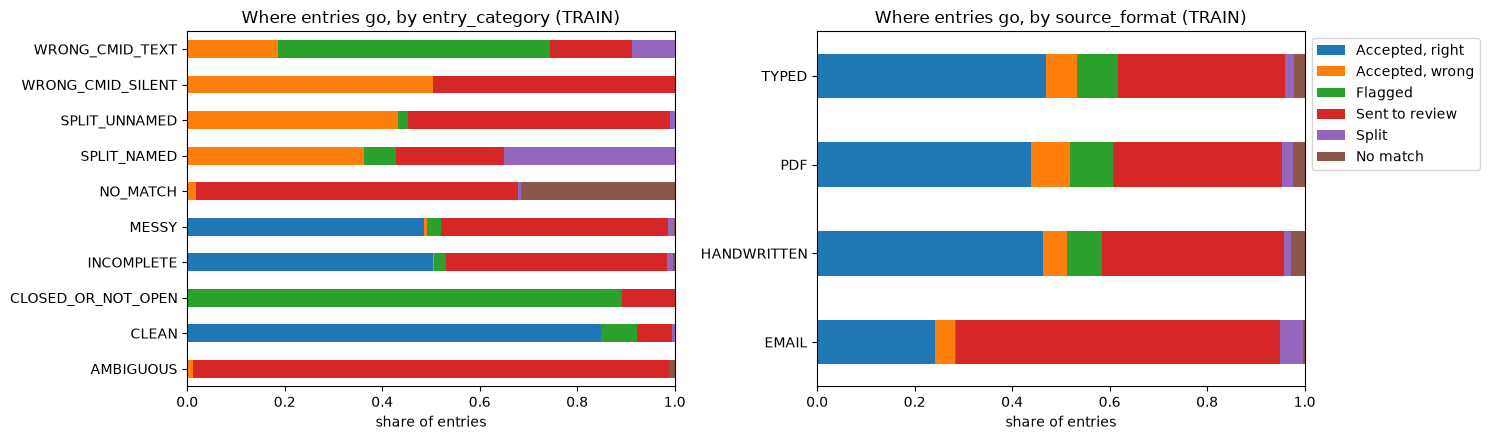

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharex=True)
for ax, col in zip(axes, ["key_entry_category", "source_format"]):
    shares = chosen_train.groupby(col)["outcome"].value_counts(normalize=True).unstack(fill_value=0).reindex(columns=OUTCOMES, fill_value=0)
    shares.plot.barh(stacked=True, ax=ax, xlim=(0, 1), legend=False, title=f"Where entries go, by {col.replace('key_', '')} ({TUNE})")
    ax.set(xlabel="share of entries", ylabel="")
axes[1].legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

- **Clean entries** do well: 85% get the right decision and 92% the right matter.
- **Incomplete and messy entries** are where review piles up, because the narrative often doesn't point to one matter.
- **Splits** are the weakest. Named splits are caught only when both matters are named by key term, and unnamed splits almost never are.
- **Emails** go to review most often: the body usually gives the client, but a task cue alone isn't enough to accept.

### Silent errors

In [14]:
silent = chosen_train[chosen_train["outcome"] == "Accepted, wrong"]
by_design = silent["key_silent_error"] == "Y"
print(f"{len(silent)} silent errors out of {(chosen_train['action'] == 'AUTO_MATCH').sum()} auto-accepts | "
      f"by design: {by_design.sum()} | catchable: {(~by_design).sum()}")
silent[~by_design]["key_entry_category"].value_counts().rename("catchable").to_frame()

172 silent errors out of 1409 auto-accepts | by design: 70 | catchable: 102


,catchable
key_entry_category,
SPLIT_UNNAMED,42
SPLIT_NAMED,28
WRONG_CMID_TEXT,21
MESSY,4
NO_MATCH,3
INCOMPLETE,2
AMBIGUOUS,2


- **By design:** 70 of the 139 silent-by-design entries are still accepted. `require_history` catches the other half by sending CMIDs the timekeeper has never billed to review.
- **Catchable:** mostly splits (70) and wrong CMIDs with a vague narrative (21). Splits are where notebook 04 has the most room to help.

### Reviewer shortlist

In [15]:
reviewed = chosen_train[(chosen_train["action"] == "NEEDS_REVIEW") & (chosen_train["key_true_cmid"] != "NONE")]
print(f"True matter in the top 3 for {reviewed['in_shortlist'].mean():.0%} of {len(reviewed)} reviewed entries")

True matter in the top 3 for 66% of 954 reviewed entries


- Two out of three times the reviewer picks from three matters instead of searching all 103.

## 7. Check on VAL (once)

Both methods with the chosen settings. Nothing changes after this. Results are shown for all entries and for the non-trivial ones (`KEY: Trivial = N`).

In [16]:
final_runs = {}
for split, table in [(TUNE, train_pairs), (CHECK, val_pairs)]:
    final_runs[("status quo", split)] = evaluate(table, chosen, status_quo)
    final_runs[("rules", split)] = evaluate(table, chosen)

rows = {}
for (method, split), scored in final_runs.items():
    rows[(method, split, "all")] = summarize(scored)
    rows[(method, split, "non-trivial")] = summarize(scored[scored["key_trivial"] == "N"])
comparison = pd.DataFrame(rows).T
comparison.index.names = ["method", "split", "entry_set"]
comparison[["auto_precision", "decided_precision", "review_share", "silent_errors", "silent_by_design", "silent_catchable",
            "action_accuracy", "no_match_precision"]].round(3)

auto_precision  decided_precision  review_share  \
method     split entry_set                                                      
status quo TRAIN all                   0.698              0.698         0.549   
                 non-trivial           0.294              0.294         0.740   
rules      TRAIN all                   0.878              0.880         0.382   
                 non-trivial           0.784              0.793         0.489   
status quo VAL   all                   0.688              0.688         0.567   
                 non-trivial           0.277              0.277         0.753   
rules      VAL   all                   0.900              0.902         0.391   
                 non-trivial           0.817              0.827         0.508   

                              silent_errors  silent_by_design  \
method     split entry_set                                      
status quo TRAIN all                  381.0             139.0   
                 non-trivial          381.0             139.0   
rules      TRAIN all                  172.0              70.0   
                 non-trivial          172.0              70.0   
status quo VAL   all                   81.0              32.0   
                 non-trivial           81.0              32.0   
rules      VAL   all                   28.0              19.0   
                 non-trivial           28.0              19.0   

                              silent_catchable  action_accuracy  \
method     split entry_set                                        
status quo TRAIN all                     242.0            0.424   
                 non-trivial             242.0            0.223   
rules      TRAIN all                     102.0            0.596   
                 non-trivial             102.0            0.508   
status quo VAL   all                      49.0            0.414   
                 non-trivial              49.0            0.223   
rules      VAL   all                       9.0            0.602   
                 non-trivial               9.0            0.517   

                              no_match_precision  
method     split entry_set                        
status quo TRAIN all                         NaN  
                 non-trivial                 NaN  
rules      TRAIN all                       0.917  
                 non-trivial               0.917  
status quo VAL   all                         NaN  
                 non-trivial                 NaN  
rules      VAL   all                       0.933  
                 non-trivial               0.933

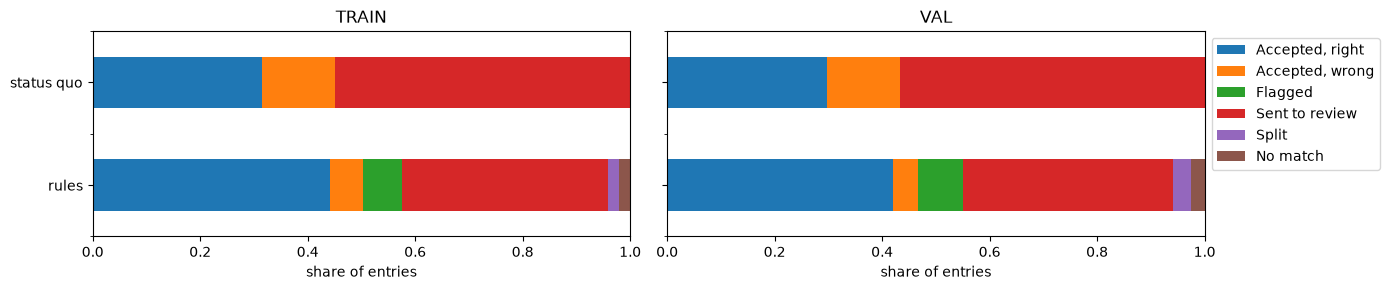

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3), sharey=True)
for ax, split in zip(axes, [TUNE, CHECK]):
    outcome_shares({m: final_runs[(m, split)] for m in ["status quo", "rules"]}).plot.barh(stacked=True, ax=ax, xlim=(0, 1), legend=False, title=split)
    ax.set_xlabel("share of entries")
axes[0].invert_yaxis()
axes[1].legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

- **Rules vs. status quo on VAL:** 39% sent to review instead of 57%, with auto precision of 90% instead of 69%.
- **Catchable silent errors** drop from 49 to 9. The other 19 are silent by design.
- **Non-trivial entries:** auto precision is 82% vs. 28%, so most of the status quo's precision comes from CMIDs that were already right.
- VAL is about the same as TRAIN or slightly better, so the settings didn't overfit.

### `NO_MATCH`

A wrong `NO_MATCH` sends a real client's time to new-client intake, so both how many are caught and how many calls are right matter.

In [18]:
no_match_rows = {}
for split in [TUNE, CHECK]:
    scored = final_runs[("rules", split)]
    expected, decided = scored["key_expected_action"] == "NO_MATCH", scored["action"] == "NO_MATCH"
    no_match_rows[split] = {"NO_MATCH entries": expected.sum(), "caught": decided[expected].mean(),
                            "NO_MATCH calls": decided.sum(), "calls right": expected[decided].mean()}
pd.DataFrame(no_match_rows).T.round(2)

,NO_MATCH entries,caught,NO_MATCH calls,calls right
TRAIN,174.0,0.32,60.0,0.92
VAL,37.0,0.38,15.0,0.93


- When the rules call `NO_MATCH`, they're right about 92% of the time, but they only catch about a third of `NO_MATCH` entries. The rest go to review, which is safe.
- New matters at known clients are the hard case: they look just like a CMID typo.

## 8. Save

- `03_decisions.csv`: one row per TRAIN and VAL entry from the chosen rules, with the reason and shortlist
- `03_comparison.csv`: headline numbers for each method, split, and entry set. Notebook 04 adds its rows.
- `03_config.json`: the chosen settings

In [19]:
decisions = pd.concat([final_runs[("rules", s)] for s in [TUNE, CHECK]], ignore_index=True)
decisions.to_csv(RESULTS_DIR / "03_decisions.csv", index=False)
comparison.reset_index().to_csv(RESULTS_DIR / "03_comparison.csv", index=False)
(RESULTS_DIR / "03_config.json").write_text(json.dumps({"rules": chosen, "precision_target": PRECISION_TARGET}, indent=2, default=str))
print("Saved:", ", ".join(p.name for p in sorted(RESULTS_DIR.glob("03_*"))))

Saved: 03_comparison.csv, 03_config.json, 03_decisions.csv


## 9. Findings

- **Rules vs. status quo (VAL):** 39% sent to review instead of 57%, auto precision 90% instead of 69%, and catchable silent errors down from 49 to 9.
- **The 98% target isn't reached.** The best on TRAIN is 88% decided precision. More precision costs more review: the two biggest settings take review from 22% to 38%. How much review is acceptable is a team call.
- **Silent by design:** checking timekeeper history catches about half of them.
- **Splits** are most of the catchable silent errors left.
- **`NO_MATCH`:** calls are right about 92% of the time, but only about a third of new clients and matters are caught.
- **Shortlist:** the true matter is in the top 3 for two thirds of reviewed entries.

## Limitations

- The data is synthetic and built from phrase banks, so real entries will likely score lower.
- The rules give yes/no decisions with no confidence score, so there's no single dial for trading precision against review.
- Task cues marked `FIRM` and generic ones like "closing" or "tax" still need a check by someone who has billed time.

## Next steps

- `04_classifier`: a gradient-boosted model on the same features, with and without sentence embeddings, scored the same way and added to `03_comparison.csv`.
- Cases to look at first: splits, entries with no narrative vote, and `NO_MATCH`.
- The final 03 vs. 04 comparison runs once on TEST and the holdout file.